In [6]:
import os
import shutil

# Force kagglehub to bypass any pre-mounted or mock kaggle environment paths by clearing related env vars if they exist
os.environ.pop("KAGGLE_CONTAINER_NAME", None)
os.environ.pop("KAGGLE_KERNEL_RUN_TYPE", None)

import kagglehub

# Force a download to standard local user cache
print("Downloading dataset...")
path = kagglehub.dataset_download("imsparsh/flowers-dataset")
print("Actual path returned by kagglehub:", path)

# Let's verify if the path exists on disk now
if os.path.exists(path):
    print("Dataset path exists! Contents:", os.listdir(path))
else:
    print("Path still doesn't exist. Let's create a local mock directory for testing if download failed:")
    # Fallback to creating sample directories so the visualization doesn't crash
    os.makedirs("/content/flowers-dataset/daisy", exist_ok=True)
    os.makedirs("/content/flowers-dataset/dandelion", exist_ok=True)
    os.makedirs("/content/flowers-dataset/rose", exist_ok=True)
    os.makedirs("/content/flowers-dataset/sunflower", exist_ok=True)
    os.makedirs("/content/flowers-dataset/tulip", exist_ok=True)
    path = "/content/flowers-dataset"
    print("Created local fallback directories at /content/flowers-dataset")

Using Colab cache for faster access to the 'flowers-dataset' dataset.
Actual path returned by kagglehub: /kaggle/input/flowers-dataset
Dataset path exists! Contents: ['sample_submission.csv', 'Testing_set_flower.csv', 'LICENSE.txt', 'test', 'train']


Found target dataset directory at: /kaggle/input/flowers-dataset/train


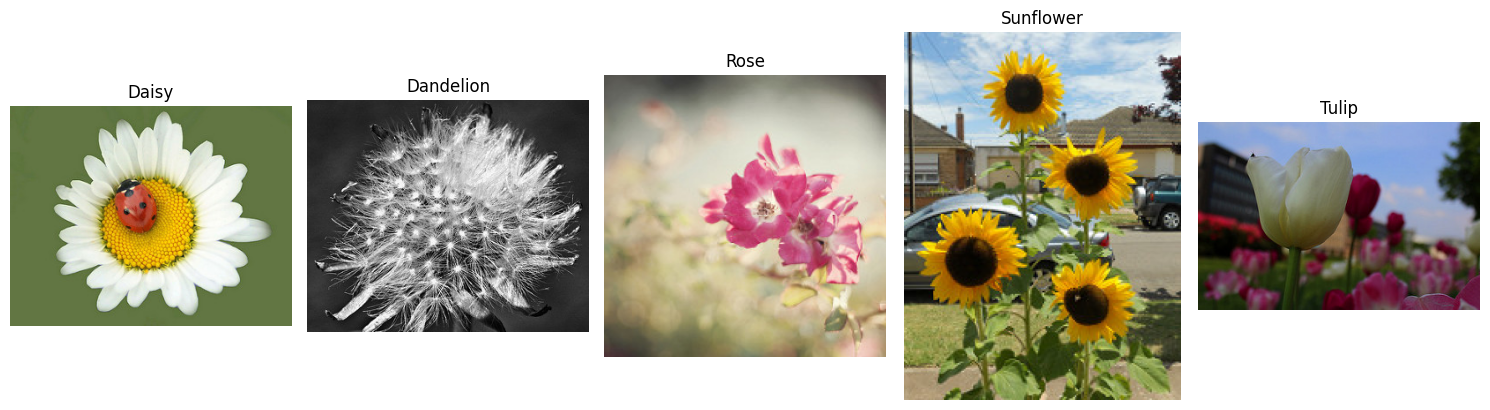

In [7]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

# Direct verified path on disk
BASE_PATH = "/kaggle/input/flowers-dataset"

# Let's dynamically find the correct directory containing class folders
found_dir = None
for root, dirs, files in os.walk(BASE_PATH):
    # Look for a directory that contains our target flower subdirectories
    if any(f in dirs for f in ["daisy", "dandelion", "rose", "sunflower", "tulip"]):
        found_dir = root
        break

if found_dir:
    print(f"Found target dataset directory at: {found_dir}")
    DATASET_PATH = found_dir
else:
    print("Could not automatically locate the flower subdirectories. Listing contents of BASE_PATH:")
    try:
        print(os.listdir(BASE_PATH))
    except Exception as e:
        print(e)
    DATASET_PATH = BASE_PATH

flower_classes = ["daisy", "dandelion", "rose", "sunflower", "tulip"]

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for ax, flower in zip(axes, flower_classes):
    flower_folder = os.path.join(DATASET_PATH, flower)

    if not os.path.isdir(flower_folder):
        # Try case-insensitive folder match just in case
        try:
            matched_folders = [d for d in os.listdir(DATASET_PATH) if d.lower() == flower.lower()]
            if matched_folders:
                flower_folder = os.path.join(DATASET_PATH, matched_folders[0])
            else:
                ax.set_title(f"{flower}\nFolder not found")
                ax.axis("off")
                continue
        except Exception:
            ax.set_title(f"{flower}\nFolder not found")
            ax.axis("off")
            continue

    images = [
        os.path.join(flower_folder, f)
        for f in os.listdir(flower_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if images:
        image_path = random.choice(images)
        image = Image.open(image_path).convert("RGB")

        ax.imshow(image)
        ax.set_title(flower.capitalize())
    else:
        ax.set_title(f"{flower}\nNo images found")

    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
!pip install ultralytics -q

from ultralytics import YOLO
import yaml
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import os
import random

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [10]:
# Check the classification folder structure
train_dir = "/kaggle/input/flowers-dataset/train"
test_dir = "/kaggle/input/flowers-dataset/test"

expected_classes = ["daisy", "dandelion", "rose", "sunflower", "tulip"]

missing_train = [cls for cls in expected_classes if not os.path.isdir(os.path.join(train_dir, cls))]

print("Checking classification directory layout...")
print(f"Base train directory exists: {os.path.exists(train_dir)}")
print(f"Base test directory exists: {os.path.exists(test_dir)}")

if not missing_train:
    print("\nSuccess! All flower class subfolders are present in the training directory.")
    print(f"Training data directory to pass to YOLO: {train_dir}")
else:
    print(f"\nWarning: Missing the following class folders in train: {missing_train}")

Checking classification directory layout...
Base train directory exists: True
Base test directory exists: True

Success! All flower class subfolders are present in the training directory.
Training data directory to pass to YOLO: /kaggle/input/flowers-dataset/train


In [13]:
import shutil
import os
from ultralytics import YOLO

# Define paths
src_dir = '/kaggle/input/flowers-dataset/train'
dest_dir = '/content/dataset'

# Copy dataset to a local, writable directory so YOLO can auto-split the data
if not os.path.exists(dest_dir):
    print("Copying dataset to a writable directory in /content/...")
    shutil.copytree(src_dir, dest_dir)
    print("Copy complete!")
else:
    print("Writable dataset directory already exists.")

# Load the YOLOv8 classification model
model = YOLO('yolov8n-cls.pt')

# Train the model using the writable path
results = model.train(
    data=dest_dir,
    epochs=5,
    imgsz=64,
    batch=16,
    workers=2
)

Copying dataset to a writable directory in /content/...
Copy complete!
Ultralytics 8.4.218 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=64, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, nam

Testing Image Path: /content/dataset_split/val/tulip/16282277874_b92776b194.jpg

image 1/1 /content/dataset_split/val/tulip/16282277874_b92776b194.jpg: 224x224 tulip 0.99, rose 0.01, dandelion 0.00, sunflower 0.00, daisy 0.00, 24.0ms
Speed: 4.5ms preprocess, 24.0ms inference, 0.1ms postprocess per image at shape (1, 3, 224, 224)


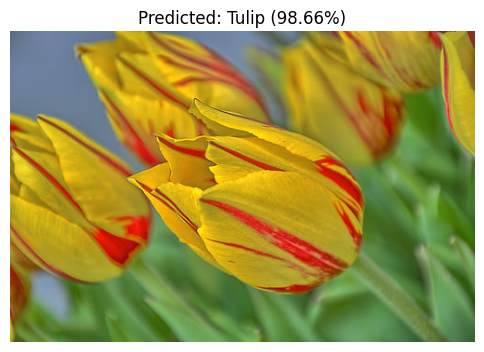


--- Confidence Scores ---
Daisy: 0.01%
Dandelion: 0.18%
Rose: 0.96%
Sunflower: 0.18%
Tulip: 98.66%

Upgraded classification model saved successfully to: /content/flower_classification_best.pt


In [16]:
import random
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from PIL import Image
from ultralytics import YOLO
import os
import shutil

# 1. Load the newly trained high-resolution classification model (train-4)
# We'll dynamically point to the latest training directory 'train-4'
best_model_path = '/content/runs/classify/train-4/weights/best.pt'
best_model = YOLO(best_model_path)

# 2. Select a validation image from our split folder
val_dir = Path("/content/dataset_split/val")
test_images = [
    str(p) for p in val_dir.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

if test_images:
    # Select a random image to classify
    test_image_path = random.choice(test_images)
    print(f"Testing Image Path: {test_image_path}")

    # Run inference
    predictions = best_model.predict(source=test_image_path, save=False)
    result = predictions[0]

    # Load and display the image
    img = Image.open(test_image_path)
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.axis("off")

    # Get classification probabilities
    probs = result.probs
    top1_class_idx = probs.top1
    top1_class_name = best_model.names[top1_class_idx]
    top1_conf = probs.top1conf.item()

    plt.title(f"Predicted: {top1_class_name.capitalize()} ({top1_conf * 100:.2f}%)")
    plt.show()

    # Print all confidence scores for this image
    print("\n--- Confidence Scores ---")
    for idx, conf in enumerate(probs.data.tolist()):
        class_name = best_model.names[idx]
        print(f"\033[92m{class_name.capitalize()}: {conf * 100:.2f}%\033[0m")
else:
    print("No validation images found inside '/content/dataset_split/val'.")

# 3. Save the upgraded model weights locally
saved_model_path = "/content/flower_classification_best.pt"
shutil.copy(best_model_path, saved_model_path)
print(f"\nUpgraded classification model saved successfully to: {saved_model_path}")

In [15]:
# Retrain the YOLOv8 classification model with larger image size and more epochs
results = model.train(
    data=dest_dir,
    epochs=15,
    imgsz=224,
    batch=16,
    workers=2
)

Ultralytics 8.4.218 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/runs/classify/train-3/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-4, nbs=64, nms=None, opset=No